In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("WB_AFS.csv")

pd.set_option("display.max_columns", None)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (4287, 41)
       STRUCTURE                STRUCTURE_ID ACTION FREQ REF_AREA  \
0  datastructure  WB.DATA360:DS_DATA360(1.3)      I    A      KGZ   
1  datastructure  WB.DATA360:DS_DATA360(1.3)      I    A      KGZ   
2  datastructure  WB.DATA360:DS_DATA360(1.3)      I    A      KGZ   
3  datastructure  WB.DATA360:DS_DATA360(1.3)      I    A      KGZ   
4  datastructure  WB.DATA360:DS_DATA360(1.3)      I    A      KGZ   

     INDICATOR SEX AGE URBANISATION UNIT_MEASURE COMP_BREAKDOWN_1  \
0  AG_SH_OFFFR  _Z  _Z           _Z           PT               _Z   
1  AG_SH_OFFFR  _Z  _Z           _Z           PT               _Z   
2  AG_SH_OFFFR  _Z  _Z           _Z           PT               _Z   
3  AG_SH_OFFFR  _Z  _Z           _Z           PT               _Z   
4  AG_SH_OFFFR  _Z  _Z           _Z           PT               _Z   

  COMP_BREAKDOWN_2 COMP_BREAKDOWN_3  TIME_PERIOD  OBS_VALUE AGG_METHOD  \
0               _Z               _Z         2018  13.309387         _Z

In [2]:
print(df.info())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nYear range:")
print(df["TIME_PERIOD"].min(), "-", df["TIME_PERIOD"].max())

print("\nEmployment indicators:")
print(df["INDICATOR_LABEL"].value_counts())

print("\nCountries:")
print(df["REF_AREA_LABEL"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 41 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   STRUCTURE               4287 non-null   object 
 1   STRUCTURE_ID            4287 non-null   object 
 2   ACTION                  4287 non-null   object 
 3   FREQ                    4287 non-null   object 
 4   REF_AREA                4287 non-null   object 
 5   INDICATOR               4287 non-null   object 
 6   SEX                     4287 non-null   object 
 7   AGE                     4287 non-null   object 
 8   URBANISATION            4287 non-null   object 
 9   UNIT_MEASURE            4287 non-null   object 
 10  COMP_BREAKDOWN_1        4287 non-null   object 
 11  COMP_BREAKDOWN_2        4287 non-null   object 
 12  COMP_BREAKDOWN_3        4287 non-null   object 
 13  TIME_PERIOD             4287 non-null   int64  
 14  OBS_VALUE               4213 non-null   

In [3]:
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nTotal missing employment values:")
print(df["OBS_VALUE"].isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate country-indicator-year combinations:")
print(df.duplicated(subset=["REF_AREA", "INDICATOR", "TIME_PERIOD"]).sum())

print("\nEmployment value range:")
print(df["OBS_VALUE"].min(), "-", df["OBS_VALUE"].max())

print("\nObservation statuses:")
print(df["OBS_STATUS_LABEL"].value_counts())

Missing values:
OBS_VALUE           74
STRUCTURE_ID         0
ACTION               0
FREQ                 0
REF_AREA             0
INDICATOR            0
SEX                  0
AGE                  0
STRUCTURE            0
URBANISATION         0
UNIT_MEASURE         0
COMP_BREAKDOWN_2     0
COMP_BREAKDOWN_1     0
COMP_BREAKDOWN_3     0
TIME_PERIOD          0
dtype: int64

Total missing employment values:
74

Duplicate rows:
0

Duplicate country-indicator-year combinations:
0

Employment value range:
2.1755695 - 41.323517

Observation statuses:
OBS_STATUS_LABEL
Normal value     4213
Missing value      74
Name: count, dtype: int64


In [4]:
us_df = df[df["REF_AREA"] == "USA"].copy()

print("USA dataset shape:", us_df.shape)

print(us_df[["TIME_PERIOD", "OBS_VALUE", "INDICATOR_LABEL"]].head())

print("\nYear range:")
print(us_df["TIME_PERIOD"].min(), "-", us_df["TIME_PERIOD"].max())

print("\nMissing values:")
print(us_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(us_df.duplicated().sum())

USA dataset shape: (25, 41)
      TIME_PERIOD  OBS_VALUE            INDICATOR_LABEL
4087         2000  12.837346  Off-Farm Employment Share
4088         2001  13.009794  Off-Farm Employment Share
4089         2002  12.992404  Off-Farm Employment Share
4090         2003  12.871120  Off-Farm Employment Share
4091         2004  12.960812  Off-Farm Employment Share

Year range:
2000 - 2024

Missing values:
0

Duplicate rows:
0


In [5]:
employment_cleaned = us_df[[
    "TIME_PERIOD",
    "REF_AREA_LABEL",
    "INDICATOR_LABEL",
    "OBS_VALUE",
    "UNIT_MEASURE_LABEL",
    "OBS_STATUS_LABEL"
]].copy()

employment_cleaned = employment_cleaned.rename(columns={
    "TIME_PERIOD": "Year",
    "REF_AREA_LABEL": "Country",
    "INDICATOR_LABEL": "Employment_Indicator",
    "OBS_VALUE": "Employment_Share_Percent",
    "UNIT_MEASURE_LABEL": "Unit",
    "OBS_STATUS_LABEL": "Observation_Status"
})

employment_cleaned["Year"] = pd.to_numeric(
    employment_cleaned["Year"], errors="coerce"
).astype("Int64")

employment_cleaned["Employment_Share_Percent"] = pd.to_numeric(
    employment_cleaned["Employment_Share_Percent"], errors="coerce"
)

employment_cleaned = employment_cleaned.sort_values("Year").reset_index(drop=True)

print(employment_cleaned.head(10))
print("\nFinal shape:", employment_cleaned.shape)

   Year        Country       Employment_Indicator  Employment_Share_Percent  \
0  2000  United States  Off-Farm Employment Share                 12.837346   
1  2001  United States  Off-Farm Employment Share                 13.009794   
2  2002  United States  Off-Farm Employment Share                 12.992404   
3  2003  United States  Off-Farm Employment Share                 12.871120   
4  2004  United States  Off-Farm Employment Share                 12.960812   
5  2005  United States  Off-Farm Employment Share                 12.908974   
6  2006  United States  Off-Farm Employment Share                 12.716202   
7  2007  United States  Off-Farm Employment Share                 12.784266   
8  2008  United States  Off-Farm Employment Share                 11.901183   
9  2009  United States  Off-Farm Employment Share                 11.861748   

         Unit Observation_Status  
0  Percentage       Normal value  
1  Percentage       Normal value  
2  Percentage       Norma

In [6]:
print("Missing values:")
print(employment_cleaned.isnull().sum())

print("\nDuplicate rows:")
print(employment_cleaned.duplicated().sum())

print("\nDuplicate years:")
print(employment_cleaned["Year"].duplicated().sum())

print("\nEmployment percentage range:")
print(employment_cleaned["Employment_Share_Percent"].min())
print(employment_cleaned["Employment_Share_Percent"].max())

print("\nYear coverage:")
print(employment_cleaned["Year"].min(), "-", employment_cleaned["Year"].max())

print("\nFinal dataset:")
print(employment_cleaned)

Missing values:
Year                        0
Country                     0
Employment_Indicator        0
Employment_Share_Percent    0
Unit                        0
Observation_Status          0
dtype: int64

Duplicate rows:
0

Duplicate years:
0

Employment percentage range:
10.973975
13.009794

Year coverage:
2000 - 2024

Final dataset:
    Year        Country       Employment_Indicator  Employment_Share_Percent  \
0   2000  United States  Off-Farm Employment Share                 12.837346   
1   2001  United States  Off-Farm Employment Share                 13.009794   
2   2002  United States  Off-Farm Employment Share                 12.992404   
3   2003  United States  Off-Farm Employment Share                 12.871120   
4   2004  United States  Off-Farm Employment Share                 12.960812   
5   2005  United States  Off-Farm Employment Share                 12.908974   
6   2006  United States  Off-Farm Employment Share                 12.716202   
7   2007  United S

In [7]:
employment_cleaned.to_csv("employment_cleaned.csv", index=False)

print("CLEAN")

CLEAN


In [8]:
report = {
    "Original rows": len(df),
    "Original columns": len(df.columns),
    "Countries in original dataset": df["REF_AREA"].nunique(),
    "Original missing employment values": df["OBS_VALUE"].isnull().sum(),
    "Original duplicate rows": df.duplicated().sum(),
    "USA rows after filtering": len(employment_cleaned),
    "USA missing values after cleaning": employment_cleaned.isnull().sum().sum(),
    "USA duplicate rows after cleaning": employment_cleaned.duplicated().sum(),
    "First year": employment_cleaned["Year"].min(),
    "Last year": employment_cleaned["Year"].max(),
    "Employment indicator": employment_cleaned["Employment_Indicator"].iloc[0],
    "Employment unit": employment_cleaned["Unit"].iloc[0]
}

for key, value in report.items():
    print(f"{key}: {value}")

pd.Series(report).to_csv("employment_data_quality_report.csv")

Original rows: 4287
Original columns: 41
Countries in original dataset: 172
Original missing employment values: 74
Original duplicate rows: 0
USA rows after filtering: 25
USA missing values after cleaning: 0
USA duplicate rows after cleaning: 0
First year: 2000
Last year: 2024
Employment indicator: Off-Farm Employment Share
Employment unit: Percentage


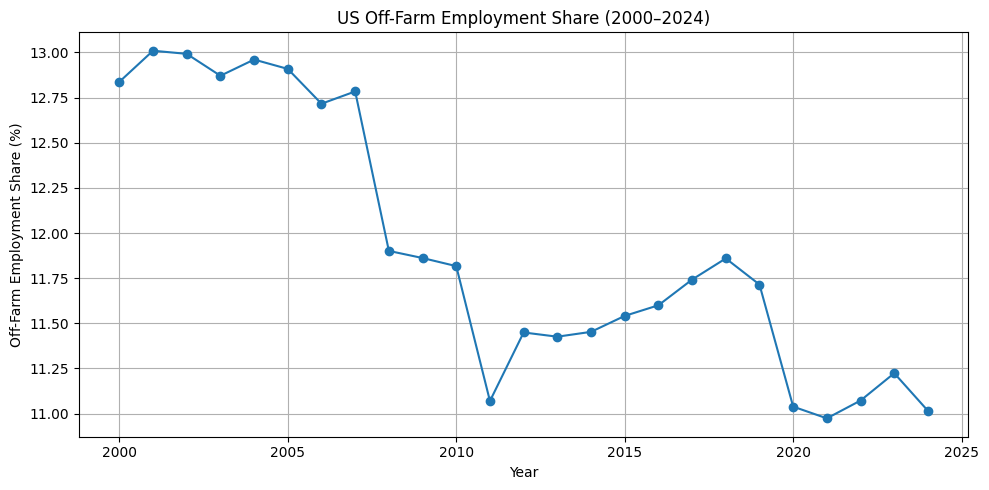

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    employment_cleaned["Year"],
    employment_cleaned["Employment_Share_Percent"],
    marker="o"
)

plt.title("US Off-Farm Employment Share (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Off-Farm Employment Share (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig("employment_trend.png")
plt.show()